# Notebook 02: The Divisibility Condition

**Goal:** Define divisibility precisely, implement the test, and show that
classical Markov chains always pass it.

By the end of this notebook you will be able to:
- State the divisibility condition as a matrix equation
- Use `check_divisibility()` to test a process (it needs the matrices it inverts to be non-singular,
  and returns `divisible: None`, undecided, when one is not)
- Explain intuitively why Markov chains are always divisible

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

---
> ### 📓 Annotated study copy
>
> Working copy of `02_divisibility.ipynb`, with study material added between the original cells.
> Added sections are marked **📖 In depth**, **🔭 Looking ahead**, **🔍 Reading the code**,
> **🧭** (orientation and cell guides), **📘 Glossary**, **📚 From the papers**,
> **🧮 Worked derivation**, and **📝 Recap**. Every other cell comes from
> `02_divisibility.ipynb`, and the shared markdown reads the same in both.
>
> Companion to `01_stochastic_processes_annotated.ipynb`.
>
> The added material covers the inverse-free (linear-programming) divisibility test,
> `PairwiseProcess`, and the places where the inverse-based test is structurally
> unavailable rather than merely inconclusive.
>
> No code cell has been re-executed, so every stored output is from the original run.
> Earlier copies are in `notebooks/_pre-2026-09-08/`.
---

<!-- expansion:02:before-you-start -->
### 🧭 Before you start

**What this notebook is for.** Notebook 01 defined a stochastic process as a family of transition matrices. This notebook asks one question about such a family: *can the evolution from an early time to a late time be split into two legitimate steps at a time in between?* That is **divisibility**. Much of the rest of the lab is about processes that fail it (the qubit in 03, the double slit in 05) and about how an environment restores it (division events in 06), so here we pin down what passing means, build the test, and show that every classical Markov chain passes.

**What you need.** Matrix multiplication and the idea of an inverse (numpy computes it); column-stochastic matrices from notebook 01; for Section 2, the matrix exponential $e^{Lt}$ (a worked derivation covers it). No quantum mechanics; forward references to it are flagged.

**How long.** The code runs in seconds. Plan 60 to 90 minutes with the annotations, more if you try the experiments.

**How to run it.** Use **Kernel > Restart & Run All**, or press **Shift+Enter** cell by cell. The first code cell adds the folder one level up (`..`) to the import path, because everything comes from the `isp/` package beside `notebooks/`: `isp/stochastic.py` (process classes), `isp/divisibility.py` (the tests), `isp/visualization.py` (heatmaps). A `ModuleNotFoundError` for `isp` means Jupyter was started from another folder. Nothing here is random, so a re-run should reproduce the stored outputs.


<!-- expansion:02:glossary -->
### 📘 Glossary

- **State / configuration.** One of the finitely many things the system can be doing (here `"0"` and `"1"`).
- **Transition matrix $T(t, t')$, or $\Gamma(t \leftarrow t')$ in the papers.** Entry $(i, j)$ is the probability of state $i$ at the later time $t$ given state $j$ at the earlier time $t'$. Same object, two notations.
- **Column-stochastic matrix.** Every entry $\ge 0$, every column sums to 1. Every legitimate transition matrix is one.
- **Pseudo-stochastic matrix.** Columns sum to 1 but some entries are negative, so it is not a table of probabilities.
- **Composition law.** $T(t_3, t_1) = T(t_3, t_2)\,T(t_2, t_1)$.
- **Divisible / indivisible.** Divisible: for every intermediate time, a legitimate stochastic matrix makes the composition law hold. Indivisible: at least once, none does. (Barandes also uses *indivisible stochastic process* for the whole class of processes not *required* to be divisible, which includes divisible ones as special cases; in this notebook "indivisible" means the condition actually fails.)
- **Intermediate (candidate) matrix.** The $T(t_3, t_2)$ the test solves for. Derived, not given.
- **Division event.** A time from which the process can be restarted using the present distribution alone. The initial time is always one.
- **Markov property.** The latest state screens off all earlier history.
- **Generator $L$.** Rate matrix of a continuous-time Markov chain: off-diagonals $\ge 0$, columns sum to 0. Norris calls it a *Q-matrix* (rows sum to 0 in his convention).
- **Semigroup property.** $e^{L(s+t)} = e^{Ls}e^{Lt}$, the Markov chain's composition law.
- **Time-(in)homogeneous.** Homogeneous: $T$ depends only on elapsed time. Inhomogeneous: also on when you start.
- **Singular, rank.** Singular means determinant 0, so no inverse. Rank counts independent columns; a rank-1 $2\times 2$ stochastic matrix sends both states to the same distribution.
- **Permutation matrix.** A 0/1 stochastic matrix that only relabels states.
- **Linear program, witness, $L_1$ defect.** An LP decides whether linear constraints have a solution; the solution found is the *witness*. The defect is the smallest $\lVert MA - B\rVert_1$ over valid $M$, zero exactly when divisible.
- **Indivisibility signature.** This repo's score: the size of the most negative entry in any candidate (0 if none; triples with a singular matrix are skipped).
- **P-/CP-divisibility.** Open-quantum-systems analogues, used only in the Looking-ahead cell near the end.


In [1]:
#import a bunch of python libraries
import sys, os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from isp.stochastic import StochasticProcess, make_markov_chain
from isp.divisibility import check_divisibility, indivisibility_signature
from isp.visualization import plot_transition_matrix

## 1. The Divisibility Condition

A process with transition matrices $\{T(t_i, t_j)\}$ is **divisible** if,
for every triple of times $t_1 < t_2 < t_3$, there is a valid stochastic matrix
$T(t_3, t_2)$ — all entries ≥ 0, columns summing to 1 — such that:

$$T(t_3, t_1) = T(t_3, t_2) \cdot T(t_2, t_1)$$

When $T(t_2, t_1)$ is invertible there is exactly one candidate, found by solving for it:

$$T(t_3, t_2) = T(t_3, t_1) \cdot T(t_2, t_1)^{-1}$$

and the process is divisible at that triple exactly when this matrix is a valid stochastic matrix.
When $T(t_2, t_1)$ is singular there is no inverse, and this shortcut cannot decide the question.

Asking this for *every* triple is stronger in form than Barandes's own condition (Paper 1, eq. 6),
which conditions on the initial time only: for each $t > t' > t_0$, is there a stochastic
$\tilde\Gamma(t \leftarrow t')$ with $\Gamma(t \leftarrow t_0) = \tilde\Gamma(t \leftarrow t')\,\Gamma(t' \leftarrow t_0)$?
The two agree when the matrices are invertible.

<!-- expansion:02:papers-definition -->
### 📚 From the papers: Barandes' definition of divisibility

**The definition.** In *The Stochastic-Quantum Correspondence* (arXiv:2302.10778v3, §2.1), a process is a configuration space plus transition matrices with entries $\Gamma_{ij}(t \leftarrow t_0) = p(i, t \mid j, t_0)$ (eq. 1), non-negative with unit column sums (eqs. 2 and 3). The divisibility condition is eq. 6:

$$\Gamma(t \leftarrow t_0) = \tilde\Gamma(t \leftarrow t')\,\Gamma(t' \leftarrow t_0), \qquad t > t' > t_0,$$

with $\tilde\Gamma$ required to be a *"genuinely stochastic matrix"*. Barandes says $\Gamma$ *"will generically be indivisible"*, citing Milz and Modi (2021). He credits the term to Wolf and Cirac (2008) *"in the context of quantum channels"*, and a footnote separates it from the older idea of an *infinitely divisible* distribution.

**Why the inverse route usually fails.** *Quantum Systems as Indivisible Stochastic Processes* (Barandes, §2.2, eqs. 22 and 23) writes down exactly the candidate this notebook computes, $\Gamma(t \leftarrow t_0)\,\Gamma^{-1}(t' \leftarrow t_0)$, and says it *"will typically have negative entries, and so will form a so-called pseudo-stochastic matrix"*, because *"the inverse of a stochastic matrix can only itself be a stochastic matrix if both matrices are permutation matrices."* The same argument is in 2302.10778v3 §3.5 (eqs. 37 and 38). The worked derivation two cells down checks it for $2 \times 2$.

**Scope.** The papers claim a *generic* time-dependent transition matrix is indivisible, with explicit $2\times 2$ examples (2302.10778v3, eq. 7). The link to quantum theory is the separate stochastic-quantum correspondence, taken up from notebook 03.


### 📖 In depth: what divisibility is actually asking

#### The intuition

Think of the process as a film of a probability distribution evolving from $t_1$ to $t_3$.

**Divisibility asks: can you pause at any intermediate frame $t_2$, throw away the reel, and restart the film from nothing but what's on screen — and still get the same ending?**

If yes, the state at $t_2$ contains everything the rest of the evolution needs. The past has been fully absorbed into the present. If no, the process is somehow still "carrying" information about where it came from, and the frame at $t_2$ is not a sufficient starting point.

That is why divisibility is closely tied to memory. It is not the same thing, though: Section 2 shows processes that carry ordinary memory and still pass.

#### ⚠️ The critical distinction: which matrices are *given*, and which are *derived*

This is the single most important structural point in the notebook, and it is easy to slide past.

A stochastic process is **specified** by its transition matrices measured **from a fixed initial time** $t_0$:

$$T(t, t_0) \quad\text{for each } t > t_0 \qquad \textit{— these are the given data}$$

Every one of these must be a legitimate stochastic matrix: non-negative, columns summing to 1. That requirement is what makes the thing a *stochastic process* at all, and quantum systems satisfy it perfectly well. (Notebook 03's qubit has $T(t,t_0)_{ij} = |U(t)_{ij}|^2$, manifestly non-negative, columns summing to 1 because $U$ is unitary.)

The intermediate matrix $T(t_3, t_2)$ is **not** given. It is *derived* — when $T(t_2, t_1)$ is invertible, solved for by rearranging:

$$T(t_3, t_2) = T(t_3, t_1)\,T(t_2, t_1)^{-1}$$

**Divisibility is the question of whether that derived object is also a legitimate stochastic matrix.** Nothing guarantees it. The two given matrices are individually valid; the thing you must compute from them need not be.

> **So the correct picture is not** *"a quantum process has good transition matrices between any two times, it just lacks a single generator."* **It is:** *the matrices from the initial time are all good, and the ones that would have to bridge intermediate times generically are not.* The initial time is privileged in how the process is specified. This is Barandes' framing, with one qualification he adds: "the initial time 0 is not a unique time but is instead only one of many division events" for a system in contact with an environment (Paper 1, §3.7, p. 19). It is why he speaks of *division events* — the special times at which the process **can** be cleanly restarted.

#### Why this is a real condition and not bookkeeping

Recall from notebook 01 that a stochastic matrix satisfies two conditions: columns summing to 1, and non-negativity. When you compute $T(t_3,t_1)T(t_2,t_1)^{-1}$:

* the **column sums survive automatically** — $\mathbf{1}^T A = \mathbf{1}^T$ and $\mathbf{1}^T B = \mathbf{1}^T$ imply $\mathbf{1}^T AB^{-1} = \mathbf{1}^T$;
* **non-negativity does not.** The inverse can and does introduce negative entries.

So once the inverse exists, the divisibility test only ever has one thing to catch, and `isp/divisibility.py` is structured accordingly: it checks `negative_entries` before `normalization_violated`, and `indivisibility_signature()` measures nothing but the magnitude of the most negative entry.

<!-- expansion:02:deriv-colsums-inverse -->
### 🧮 Worked derivation: column sums always survive; non-negativity almost never does

**1. Column sums.** "Columns of $A$ sum to 1" is the single equation $\mathbf 1^{\mathsf T} A = \mathbf 1^{\mathsf T}$, with $\mathbf 1^{\mathsf T} = (1, \dots, 1)$. Let $A = T(t_3, t_1)$ and $B = T(t_2, t_1)$, both stochastic, $B$ invertible:

$$\mathbf 1^{\mathsf T} B = \mathbf 1^{\mathsf T} \;\Longrightarrow\; \mathbf 1^{\mathsf T} = \mathbf 1^{\mathsf T} B^{-1} \;\Longrightarrow\; \mathbf 1^{\mathsf T}(A B^{-1}) = (\mathbf 1^{\mathsf T} A) B^{-1} = \mathbf 1^{\mathsf T} B^{-1} = \mathbf 1^{\mathsf T}.$$

So, whenever the input matrices have unit column sums, `normalization_violated` in `check_divisibility()` can only fire through round-off.

**2. The inverse of a $2\times 2$ stochastic matrix.** Every one has the form

$$B = \begin{pmatrix} 1-a & b \\ a & 1-b \end{pmatrix},\quad a, b \in [0,1], \qquad B^{-1} = \frac{1}{1-a-b}\begin{pmatrix} 1-b & -b \\ -a & 1-a \end{pmatrix},$$

since $\det B = (1-a)(1-b) - ab = 1 - a - b$.

- $a + b < 1$: at least one off-diagonal is negative unless $a = b = 0$ (the identity).
- $a + b > 1$: at least one diagonal is negative unless $a = b = 1$ (the swap).
- $a + b = 1$: singular, no inverse (the 🔍 cells below).

Only the two permutation matrices survive, as Barandes states.

**3. So how does anything pass?** The test looks at $A B^{-1}$, not $B^{-1}$. If the process really was built as $A = C B$ with $C$ stochastic, the negatives cancel: $A B^{-1} = C B B^{-1} = C$. Divisibility is the statement that this cancellation happens; indivisibility is that for some triple it does not.


### 📖 In depth: division events — the times at which a process can be cut

Divisibility is usually stated as a yes/no property of a whole process. Barandes' own framing is finer, and it is the one worth carrying, because it turns a verdict into a *map of where the verdict fails*.

#### The definition, localized

In Barandes' usage a division event is a time $t'$ that can serve as a conditioning time: for every later $t$ there is a valid stochastic $\Gamma(t, t')$ with $\Gamma(t, t_0) = \Gamma(t, t')\,\Gamma(t', t_0)$. For testing it helps to localize this further, pair by pair.

Call an intermediate time $t_j$ a **division event** for the pair $(t_i, t_k)$ with $t_i < t_j < t_k$ if there exists a valid stochastic matrix $\Gamma(t_k, t_j)$ satisfying

$$\Gamma(t_k, t_i) \;=\; \Gamma(t_k, t_j)\,\Gamma(t_j, t_i)$$

That is the divisibility condition, asked at **one** time rather than all of them. Then:

- **divisible** = every intermediate time is a division event;
- **indivisible** = at least one is not.

So indivisibility is not a smooth global property like "non-Markovianity." It is a statement that *certain particular moments cannot be used as restart points*, and the interesting content is which ones.

#### The initial time is always a division event

By definition: the process is specified by the matrices $\Gamma(t_k, t_0)$ conditioned on $t_0$, so each of them already restarts the process from $t_0$ (formally, extending the condition to $t_j = t_i$ gives $\Gamma(t_k,t_i) = \Gamma(t_k,t_i)\,I$). Barandes builds this in: the allowed conditioning times are assumed to include an initial time. Unremarkable on its own, but it is the asymmetry flagged at the end of notebook 01:

> The matrices measured **from the initial time** are always legitimate stochastic matrices. The ones bridging two *intermediate* times need not be.

An indivisible process is therefore not one whose transition matrices are broken. Every $\Gamma(t_k, t_0)$ in this lab's models is non-negative with unit column sums: `PairwiseProcess.__post_init__` asserts that for every matrix it stores, and notebook 03's qubit, a `StochasticProcess` whose stored steps are derived bridges, still chains to the valid matrices $|U_{ij}(t)|^2$ from the initial time. What fails is the *derived* bridge between two later times.

#### The physical reading

A division event is a time at which the process can be **restarted from the present alone**. Everything the past contributed has been absorbed into "where the system is now," so an observer arriving at $t_j$, told only the current distribution, could carry the process forward correctly.

At a non-division event that fails. Reproducing the later distribution requires information the present distribution does not contain — which is memory, in the strict sense. There is no legal transition matrix from $t_j$ onward because a transition matrix is *by construction* a rule that consumes only the current state.

> This is why Barandes reads measurement and decoherence as **generating** division events rather than collapsing anything. Coupling the system to an environment destroys the coherences carrying the memory, and the process becomes cuttable at that time. Notebook 05 does exactly this on a dial: the coherence parameter $c$ slides from $c=1$ (no division event at the slit plane) to $c=0$ (the slit plane *is* a division event), and interference tracks it the whole way.

#### One caution about scope

This notebook and the next test the condition on specific finite models at specific times. The picture of the classical regime as division events becoming dense (a macroscopic system's process can be cut almost anywhere) is our paraphrase, not Barandes's wording. What he writes is that systems "in sufficiently strong contact with a repeatedly eavesdropping environment" have many division events (Paper 1, §2.1 and §3.7), which gives "a theoretical explanation for the ubiquity of Markovian stochastic dynamics" (§3.7). It is argued in the papers, not demonstrated here. Keep the two apart when reading.

*Reference: arXiv 2302.10778v3, §2.1 (divisibility, eq. 6) and §3.7 ("Division events and the Markov approximation"); and `papers to study/Barandes/3 Q Theory as ISP 2025.pdf`, §2.2.*

<!-- expansion:02:papers-division-events -->
### 📚 From the papers: division events in Barandes' words

- **Definition.** *Quantum Systems as Indivisible Stochastic Processes*, §2.2: *"Allowed conditioning times $t_0$ are called division events for the given system"*, assumed to include an initial time 0. They are *"system-centric"*, and may be exact or generated approximately *"through interactions with other systems, after marginalizing over those other systems."*
- **Derivation.** 2302.10778v3, §3.7 (*"Division events and the Markov approximation"*): after a subject system interacts with an environment up to $t'$ and the environment is marginalized out, the subject's transition matrix is *"manifestly divisible at $t'$"* (eq. 56), hence *"natural to refer to the new conditioning time $t'$ as a division event."* Decoherence follows in §3.8 and measurement from §4.
- **Why Markov models work.** Same section: if division events recur every $\delta t$ and the dynamics is time-homogeneous, the subject evolves as $(\Gamma^S)^n$ (eq. 57), a discrete-time Markov chain. Section 2 of this notebook is the other half: once Markov, divisible at every time.

Nothing in this notebook models an environment; notebook 06 does.


In [2]:
# Build a simple divisible process: three explicit steps
T1 = np.array([[0.8, 0.3], [0.2, 0.7]])
T2 = np.array([[0.7, 0.4], [0.3, 0.6]])
T3 = np.array([[0.9, 0.2], [0.1, 0.8]])

proc = StochasticProcess(
    states=["0", "1"],
    transitions=[T1, T2, T3],
    times=[0.0, 1.0, 2.0, 3.0]
)

result = check_divisibility(proc)
print("Divisible?", result["divisible"])
print("Failure mode:", result["failure_mode"])

Divisible? True
Failure mode: None


<!-- expansion:02:howto-first-test -->
### 🧭 How to use this cell / what to look at

**What it computes.** A two-state process from three hand-picked steps (step $k$ goes from `times[k]` to `times[k+1]`), then `check_divisibility()`. The function loops over every position triple $i < j < k$; with four times that is $(0,1,2)$, $(0,1,3)$, $(0,2,3)$, $(1,2,3)$. It returns at the first failure, and it also tests triples starting after the initial time.

**What to look for.** `Divisible? True`, `Failure mode: None`. That is guaranteed: a `StochasticProcess` stores increments and builds longer matrices as products, so for valid steps each candidate is just a product of later steps. By hand, $\det T_1 = 0.5$, $\det T_2 = 0.3$, $\det T_3 = 0.7$, so the singular branch cannot fire. Up to round-off, a `StochasticProcess` built from valid steps can only return `True` or `singular_matrix`. A genuine `negative_entries` needs a stored step that is not itself stochastic, which is how notebook 03's `make_qubit_sigmax_process` is built.

**Try this.**
1. Set `T2 = np.array([[1.2, -0.1], [-0.2, 1.1]])` (the class does not validate). Predict `negative_entries` at `(0.0, 1.0, 2.0)` with `min=-0.200000`. Yet `proc.transition_from_to(0, 2)` is $\begin{pmatrix}0.94 & 0.29\\0.06 & 0.71\end{pmatrix}$, perfectly valid: every matrix from the initial time is legitimate, only the bridge is not. A miniature indivisible process.
2. Set `T2` to the rank-1 `[[0.5, 0.5], [0.5, 0.5]]`. Predict `singular_matrix` at `(0.0, 2.0, 3.0)`.
3. Set `T1` to the swap `[[0, 1], [1, 0]]`. Predict still divisible: determinant $-1$, inverse is itself.


In [3]:
# Manually verify: compute T(t3,t2) candidate and inspect
T_03 = proc.transition_from_to(0, 3)   # T(t=0 → t=3)
T_01 = proc.transition_from_to(0, 1)   # T(t=0 → t=1) = T1

T_13_candidate = T_03 @ np.linalg.inv(T_01)
print("T(t3,t2) candidate:")
print(T_13_candidate)
print("\nColumn sums:", T_13_candidate.sum(axis=0))
print("All entries >= 0:", np.all(T_13_candidate >= -1e-10))

T(t3,t2) candidate:
[[0.69 0.48]
 [0.31 0.52]]

Column sums: [1. 1.]
All entries >= 0: True


<!-- expansion:02:deriv-manual-candidate -->
### 🧮 Worked derivation: why the candidate above is exactly $T_3 T_2$

`transition_from_to` multiplies stored steps latest-on-the-left, so $T(0 \to 3) = T_3 T_2 T_1$ and $T(0 \to 1) = T_1$:

$$T(0 \to 3)\,T(0 \to 1)^{-1} = T_3 T_2 T_1 T_1^{-1} = T_3 T_2 = \begin{pmatrix}0.9 & 0.2\\0.1 & 0.8\end{pmatrix}\begin{pmatrix}0.7 & 0.4\\0.3 & 0.6\end{pmatrix} = \begin{pmatrix}0.63 + 0.06 & 0.36 + 0.12\\ 0.07 + 0.24 & 0.04 + 0.48\end{pmatrix} = \begin{pmatrix}0.69 & 0.48\\0.31 & 0.52\end{pmatrix},$$

exactly the stored output. On its own, $T_1^{-1}$ has negative entries (formula above with $a = 0.2$, $b = 0.3$: $\begin{pmatrix}1.4 & -0.6\\-0.4 & 1.6\end{pmatrix}$); they cancel against the $T_1$ inside $T(0 \to 3)$. The three printed checks are the whole definition: the candidate, its column sums (always 1), and the sign check (the only one that can fail; `-1e-10` absorbs round-off).

**Try this.** Change `T_01` to `proc.transition_from_to(0, 2)`. Predict the candidate is $T_3 = \begin{pmatrix}0.9 & 0.2\\0.1 & 0.8\end{pmatrix}$. Then print `np.linalg.inv(T_01)` alone: it is $(T_2T_1)^{-1} \approx \begin{pmatrix}3.4 & -3.267\\-2.4 & 4.267\end{pmatrix}$, pseudo-stochastic like $T_1^{-1}$ (columns sum to 1, off-diagonals negative), and its negatives cancel the same way.


### 🔍 Reading the code: three things worth knowing about this test

#### (a) The intermediate matrix is *unique* — so there is nothing to search for

The condition reads "…can be satisfied by a valid stochastic matrix," which sounds like it needs a search over candidates. It doesn't. If $T(t_2,t_1)$ is invertible, then

$$X\,T(t_2,t_1) = T(t_3,t_1) \quad\Longrightarrow\quad X = T(t_3,t_1)\,T(t_2,t_1)^{-1}$$

has exactly **one** solution. So the test is: compute the single candidate, then check whether it happens to be non-negative. Either it is or it isn't; there is no second chance. That's why `check_divisibility()` is a dozen lines rather than an optimization routine.

#### (b) ⚠️ Naming trap: $t_1,t_2,t_3$ in the prose vs. `0,1,2,3` in the code

The markdown above names a generic triple $t_1 < t_2 < t_3$, **1-indexed**. The code uses **0-based positions into the `times` list**, which here has *four* entries `[0.0, 1.0, 2.0, 3.0]`. These do not line up, and the previous cell is where it bites:

```python
T_03 = proc.transition_from_to(0, 3)   # positions 0 -> 3
T_01 = proc.transition_from_to(0, 1)   # positions 0 -> 1
T_13_candidate = T_03 @ np.linalg.inv(T_01)
print("T(t3,t2) candidate:")           # <-- prose naming, not code indices
```

The variable name `T_13_candidate` uses **code indices** (position 1 → position 3). The printed label `"T(t3,t2)"` uses **prose naming** for the same object. Both are defensible; together they're confusing. When reading, fix on the code indices and translate the prose, not the other way round.

#### (c) `singular_matrix` means "undecided", not "not divisible"

Look at lines 35–46 of `isp/divisibility.py`. If $\det T(t_2,t_1) \approx 0$, the function returns:

```python
{"divisible": None, "failure_mode": "singular_matrix", ...}
```

`None` is the honest answer, because a singular $T(t_2,t_1)$ does **not** imply the process is indivisible. It means the *solve-by-inversion* strategy from (a) is unavailable. When the matrix is singular, $X\,T(t_2,t_1) = T(t_3,t_1)$ may still have solutions — infinitely many rather than one, or none at all — and one of them may be a perfectly good stochastic matrix.

The next cell builds exactly that case: a rank-1 (but entirely legitimate) transition matrix $\begin{pmatrix}0.5 & 0.5\\ 0.5 & 0.5\end{pmatrix}$, where a valid factorization demonstrably exists and the inverse test can only return `divisible: None`.

**This matters for interpretation.** A `singular_matrix` verdict is not evidence of quantum-like behavior — it is the test declining to answer. Singular transition matrices are common and thoroughly classical: any process that collapses two states into the same distribution produces one. Treat that failure mode as *"inconclusive, needs a different method"*, and reserve the indivisibility conclusion for `negative_entries`.

Notebook 03's qubit fails with `negative_entries`, so the headline result is unaffected — but the distinction is worth carrying, because `indivisibility_signature()` sidesteps the issue entirely by `continue`-ing past singular triples (lines 93–94) rather than scoring them.

In [4]:
# 🔍 Reading the code: the `singular_matrix` case, demonstrated.

# A rank-1 transition matrix. Perfectly legitimate: non-negative, columns sum to 1.
# It just sends BOTH starting states to the same 50/50 distribution.
T_collapse = np.array([[0.5, 0.5],
                       [0.5, 0.5]])
T_after    = np.array([[0.8, 0.3],
                       [0.2, 0.7]])

print(f"T_collapse is a valid stochastic matrix: "
      f"min={T_collapse.min()}, col sums={T_collapse.sum(axis=0)}")
print(f"...but it is singular:  det = {np.linalg.det(T_collapse):.1e}\n")

proc_sing = StochasticProcess(states=["0", "1"],
                              transitions=[T_collapse, T_after],
                              times=[0.0, 1.0, 2.0])

verdict = check_divisibility(proc_sing)
print(f"check_divisibility says:  divisible = {verdict['divisible']}, "
      f"failure_mode = {verdict['failure_mode']!r}")
print(f"  message: {verdict['message']}\n")

# But a valid factorization plainly EXISTS -- we built the process out of one:
print("Does a valid stochastic intermediate exist? Yes, by construction:")
print(f"  T_after @ T_collapse == T(0->2)?  "
      f"{np.allclose(T_after @ T_collapse, proc_sing.transition_from_to(0, 2))}")
print(f"  and T_after is valid: min={T_after.min()}, col sums={T_after.sum(axis=0)}")
print("\n  -> The process IS divisible. The solve-by-inverse simply cannot")
print("     recover the factorization, because inv(T_collapse) does not exist.")
print("     Read 'singular_matrix' as INCONCLUSIVE, not as indivisible.")

# Why it's inconclusive rather than wrong: the equation is underdetermined.
print(f"\n  rank(T_collapse) = {np.linalg.matrix_rank(T_collapse)} of 2"
      "  -> X @ T_collapse = T(0->2) has infinitely many solutions,")
print("     not zero. The unique-solve strategy just isn't applicable.")

T_collapse is a valid stochastic matrix: min=0.5, col sums=[1. 1.]
...but it is singular:  det = 0.0e+00

check_divisibility says:  divisible = None, failure_mode = 'singular_matrix'
  message: T(0.0,1.0) is singular — det=0.00e+00; the inverse test can't decide, use check_divisibility_lp

Does a valid stochastic intermediate exist? Yes, by construction:
  T_after @ T_collapse == T(0->2)?  True
  and T_after is valid: min=0.2, col sums=[1. 1.]

  -> The process IS divisible. The solve-by-inverse simply cannot
     recover the factorization, because inv(T_collapse) does not exist.
     Read 'singular_matrix' as INCONCLUSIVE, not as indivisible.

  rank(T_collapse) = 1 of 2  -> X @ T_collapse = T(0->2) has infinitely many solutions,
     not zero. The unique-solve strategy just isn't applicable.


<!-- expansion:02:deriv-singular-family -->
### 🧮 Worked derivation: the whole family of valid answers in the rank-1 case

**1.** Both columns of $T_{\text{collapse}}$ are $u = (0.5, 0.5)^{\mathsf T}$, so $T_{\text{collapse}} = u\,\mathbf 1^{\mathsf T}$ and $X\,T_{\text{collapse}} = (Xu)\,\mathbf 1^{\mathsf T}$: both columns equal $Xu$.

**2.** The target is $(T_{\text{after}}u)\,\mathbf 1^{\mathsf T}$, with $T_{\text{after}}u = (0.4 + 0.15,\; 0.1 + 0.35)^{\mathsf T} = (0.55, 0.45)^{\mathsf T}$.

**3.** For stochastic $X = \begin{pmatrix}a & b\\1-a & 1-b\end{pmatrix}$, $Xu = \big(\tfrac{a+b}{2}, 1 - \tfrac{a+b}{2}\big)^{\mathsf T}$, so the only condition is $a + b = 1.1$. Writing $a = 0.55 + s$, $b = 0.55 - s$:

$$X(s) = \begin{pmatrix}0.55 + s & 0.55 - s\\ 0.45 - s & 0.45 + s\end{pmatrix}, \qquad \text{valid exactly for } -0.45 \le s \le 0.45.$$

$T_{\text{after}}$ itself is $s = 0.25$. So the inverse-based test misses not one answer but a segment of them. "Compute *the* solution" is meaningless here; "does *any* valid solution exist?" (eq. 6) has a clear answer, and that is the LP formulation two cells down.

**Try this.**
1. `from isp.divisibility import check_divisibility_lp`, then `check_divisibility_lp(proc_sing)`. Predict `divisible=True` and a `witness` equal to some $X(s)$ with $|s| \le 0.45$; which $s$ the solver picks is not determined, so do not expect 0.25.
2. Set `T_after = np.array([[1.0, 0.6], [0.0, 0.4]])`. Predict target column $(0.8, 0.2)$, $a + b = 1.6$, valid range $|s| \le 0.2$.


### 📖 In depth: solving for the intermediate matrix asks a different question

The 🔍 code cell above demonstrated the `singular_matrix` case as a quirk of the implementation. It is worth being harder on it than that, because the problem is not the tolerance or the determinant check — it is that `check_divisibility()` answers a question the definition never asked.

#### Two questions that are not the same

| | the definition | what `check_divisibility` does |
|---|---|---|
| asks | does **some** stochastic $M$ satisfy $M\,\Gamma(t_1,t_0) = \Gamma(t_2,t_0)$? | compute **the** $M = \Gamma(t_2,t_0)\Gamma(t_1,t_0)^{-1}$, then check it |
| presumes | nothing | that the solution is unique, hence that the inverse exists |
| when $\Gamma(t_1,t_0)$ is singular | still perfectly well posed | undefined |

The two coincide on exactly one condition: **$\Gamma(t_1,t_0)$ invertible.** There the solution set is a single point, so "check the one candidate" and "does a candidate exist" are the same question, and inverting is a legitimate shortcut.

Off that condition the solution set is not a point. It is either empty or an infinite family — an affine subspace of matrices, intersected with the non-negativity and column-sum constraints — and no inversion can distinguish those two cases, because inversion is not available in either.

#### So `singular_matrix` is not a verdict about the physics

Read the return value literally:

```python
return {"divisible": None,
        "failure_mode": "singular_matrix", ...}     # divisibility.py:37-46
```

It sets `divisible=None`. The process may be perfectly divisible, or not; the function has lost the ability to tell, and says so. **Read `None` as "undecided", never as either verdict**, and its message points to `check_divisibility_lp`, which can decide. Notebook 05 hits precisely this: the *decohered* double slit is divisible — the LP finds an explicit witness — yet its $\Gamma(t_1,t_0)$ is singular, so `check_divisibility()` can only return `singular_matrix`.

The companion function is worse, because it does not even flag the situation:

```python
if abs(np.linalg.det(T_ij)) < tol:
    continue                                        # divisibility.py:93-94
```

`indivisibility_signature()` skips the triple and returns the maximum over whatever survived. If every triple is singular, the maximum is over nothing, and the function returns `0.0` — indistinguishable from a classical Markov chain. On the fully coherent double slit that is exactly what happens.

> ⚠️ **Neither function is wrong on the processes in notebooks 02 and 03.** The qubit's $\Gamma$ matrices are invertible away from isolated times, the inverse-based test applies, and its answers are correct — that is why the original lab got the right result. The failure is one of *coverage*: an entire class of physically natural models sits outside what the method can address, and the method reports on them anyway.

### 📖 In depth: the divisibility question is a linear program, and that is not a coincidence

Ask the existence question directly and the right algorithm falls out, because every constraint on the unknown matrix is linear.

#### Three linear constraints

Let $M$ be the unknown intermediate matrix, $A \equiv \Gamma(t_1,t_0)$ and $B \equiv \Gamma(t_2,t_0)$. $M$ must satisfy:

$$\underbrace{M A = B}_{\text{composition}} \qquad \underbrace{M_{ij} \ge 0}_{\text{entries are probabilities}} \qquad \underbrace{\textstyle\sum_i M_{ij} = 1}_{\text{columns are complete}}$$

All three are linear in the entries of $M$. Composition is linear because $A$ is a *constant* — the map $M \mapsto MA$ is a fixed linear map, not a bilinear one. So the set of admissible $M$ is an intersection of half-spaces and hyperplanes: a **polyhedron**.

"Is the process divisible at this time?" is then, exactly and with no approximation, "**is this polyhedron non-empty?**" — which is the definition of linear-programming feasibility. That is what `_intermediate_lp()` builds and hands to `scipy.optimize.linprog`.

#### The one implementation trick

`linprog` wants a vector of unknowns, not a matrix. Flatten $M$ row-major, and the composition constraint becomes

$$\operatorname{vec}(MA) \;=\; \big(I \otimes A^{\mathsf T}\big)\operatorname{vec}(M)$$

which is the line

```python
compose = sp.kron(sp.identity(n, format="csr"), sp.csr_matrix(T_ij.T))   # divisibility.py:139
```

The column-sum constraint is the other Kronecker product on the next line. Both are sparse, which is why a $24 \times 24$ slit model — $576$ unknowns — solves instantly.

#### The geometry, if you want the picture

The column-stochastic matrices of size $n$ form a product of $n$ simplices: each column is independently a point in the $(n-1)$-simplex. Right-multiplying that whole set by $A$ gives its image under a linear map — again a convex polytope. Divisibility asks whether the single point $B$ lies inside it.

- $B$ inside $\Rightarrow$ divisible: some valid $M$ has $MA = B$, and every such $M$ is a valid intermediate matrix. When several exist, the LP returns one of them, stored as `witness`.
- $B$ outside $\Rightarrow$ indivisible, and there is a *distance* from $B$ to the polytope.

That distance is the second mode of the same function. Setting `minimize_residual=True` adds $\pm$ slack variables and minimizes

$$\min_{M \ge 0,\; \mathbf 1^{\mathsf T} M = \mathbf 1^{\mathsf T}} \big\| M A - B \big\|_1$$

which is always feasible, and is zero **exactly** when the process is divisible. `divisibility_defect()` returns the largest such residual over all triples.

#### ⚠️ What the defect is, and what it is not

It is an honest **verdict**: zero or non-zero decides divisibility exactly, with no inverse and no skipped triples.

It is **not** a physical magnitude. It is an $L_1$ residual over an entire $n \times n$ matrix, so it grows with the size of the state space and with how the states are labelled. The coherent double slit reports $11.998165$; that number says "indivisible" and nothing more. It is not a quantity to compare across models, and it is not "how quantum" the process is.

> The one place a defect *does* carry physical content in this lab is notebook 05 — but there it is a different object. Not this whole-matrix residual: the entrywise defect matrix $D = \Gamma(t_2,t_0) - \Gamma(t_2,t_1)\Gamma(t_1,t_0)$, read down its **source column**. That column is the interference pattern, exactly. The scalar summarizing the whole matrix is a verdict; the single column is physics.

<!-- expansion:02:recap-1 -->
### 📝 Recap: Section 1

- A process is **given** by matrices from the initial time; divisibility asks whether the **derived** bridge between later times is also stochastic (2302.10778v3, eq. 6).
- The inverse-based candidate always has unit column sums; only non-negativity can fail, and for a genuine composition the inverse's negatives cancel.
- A stochastic matrix's inverse is stochastic only for permutations (checked by hand for $2 \times 2$).
- A **division event** is a time the process can restart from; the initial time always is one, and environments create more (§3.7).
- `singular_matrix` means "cannot answer". The rank-1 example has a whole interval of valid answers; the LP tools ask the existence question directly.


## 2. Why Markov Chains Are Always Divisible

For a time-homogeneous continuous-time Markov chain with a valid generator $L$
(off-diagonal entries ≥ 0, columns summing to 0), $T(t) = e^{Lt}$.
The composition law for matrix exponentials gives:
$$e^{L(t_3-t_1)} = e^{L(t_3-t_2)} \cdot e^{L(t_2-t_1)}$$

This identity holds for any times — Markov chains are divisible **by construction**.
The intermediate matrix is simply $T(t_3,t_2) = e^{L(t_3-t_2)}$, which is a valid
stochastic matrix for every valid generator $L$.

<!-- expansion:02:deriv-markov -->
### 🧮 Worked derivation: why $e^{Lt}$ is stochastic, and why it composes

**1. Composition.** $e^{M} = \sum_k M^k/k!$, and $e^{M_1 + M_2} = e^{M_1}e^{M_2}$ whenever $M_1, M_2$ commute. $L s$ and $L t$ always commute, so $e^{L(t_3 - t_1)} = e^{L(t_3 - t_2)}\,e^{L(t_2 - t_1)}$.

**2. Columns sum to 1.** Columns of $L$ sum to 0 (`make_markov_chain` docstring), i.e. $\mathbf 1^{\mathsf T} L = 0$, so $\mathbf 1^{\mathsf T} L^k = 0$ for $k \ge 1$ and $\mathbf 1^{\mathsf T} e^{Lt} = \mathbf 1^{\mathsf T}$.

**3. Entries stay non-negative.** For small $t$, $e^{Lt} = I + Lt + O(t^2)$: off-diagonals $\approx L_{ij}t \ge 0$, diagonals near 1. For larger $t$, $e^{Lt} = (e^{Lt/n})^n$ is a product of non-negative matrices. This needs the off-diagonals of $L$ to be non-negative; "always valid" holds only for valid generators.

**4. Two-state closed form.** For the next cell's $L = \begin{pmatrix}-0.5 & 0.3\\0.5 & -0.3\end{pmatrix}$, the eigenvalues are $0$ and $\operatorname{tr}L = -0.8$; the stationary distribution solves $-0.5\pi_0 + 0.3\pi_1 = 0$, giving $\pi = (0.375, 0.625)$. Then

$$e^{Lt} = \begin{pmatrix}\pi_0 + \pi_1 e^{-0.8t} & \pi_0(1 - e^{-0.8t})\\ \pi_1(1 - e^{-0.8t}) & \pi_1 + \pi_0 e^{-0.8t}\end{pmatrix}.$$

The bridge $e^{L(t_3 - t_2)}$ has second eigenvalue $e^{-0.8(t_3 - t_2)} \in (0, 1]$. Remember this: in the preview derivation near the end, indivisibility shows up as a bridge whose second eigenvalue would need magnitude above 1.

### 📚 From the papers: the textbook theorems

- **Norris, *Markov Chains*, Thm 2.1.1:** $P(t) = e^{tQ}$ satisfies *"$P(s+t) = P(s)P(t)$ for all s, t (semigroup property)"*, proved by the commuting argument in step 1.
- **Norris, Thm 2.1.2:** *"A matrix Q on a finite set I is a Q-matrix if and only if P(t) = e^{tQ} is a stochastic matrix for all t ≥ 0"*, proved via $P(t) = P(t/n)^n$ as in step 3.
- **Convention warning.** Norris uses row vectors: rows of $P$ sum to 1, rows of $Q$ sum to 0. Every matrix here is the transpose of his; the theorems carry over.
- **Barandes, *Quantum Systems as ISP*, §2.1:** for a Markov process the transition probabilities *"concatenate or compose over time"* (eq. 7), which is the divisibility condition (eq. 14).


In [5]:
L = np.array([[-0.5,  0.3],
              [ 0.5, -0.3]])

times = [0.0, 0.5, 1.2, 2.0, 3.5]
markov = make_markov_chain(2, L, times)

result = check_divisibility(markov)
sig = indivisibility_signature(markov)

print(f"Divisible: {result['divisible']}")
print(f"Indivisibility signature: {sig:.2e}  (should be ~0)")

Divisible: True
Indivisibility signature: 0.00e+00  (should be ~0)


<!-- expansion:02:howto-markov -->
### 🧭 How to use this cell / what to look at

**What it computes.** A Markov chain from $L$ at five uneven times, so steps $e^{L\Delta t}$ with $\Delta t = 0.5, 0.7, 0.8, 1.5$, then the yes/no test and the signature.

**What to look for.** `Divisible: True` across all ten triples, and `Indivisibility signature: 0.00e+00`, which is *exactly* zero: the function returns $\max(0, -\min)$, so a candidate with no negative entry contributes exactly 0. Anything like `1e-17` would be round-off.

**Try this.**
1. Use an invalid generator, `L = np.array([[-0.5, -0.3], [0.5, 0.3]])` (columns still sum to 0). Predict `negative_entries` at the first triple: the steps themselves now have a negative entry (top-right $-0.3(1 - e^{-0.2\Delta t})/0.2$). This is not indivisibility; even the matrices from the initial time are invalid. The test only inspects intermediates, so garbage in produces a verdict that means something else.
2. Set `times = [0.0, 30.0, 31.0]`. Predict `singular_matrix` on a chain that is divisible by construction: $\det e^{Lt} = e^{t\operatorname{tr}L} = e^{-0.8t}$, and $e^{-24} \approx 3.8\times10^{-11}$ is below `tol=1e-10`. Long times make the matrix numerically rank-1.
3. Any other valid generator, e.g. `[[-3.0, 1.0], [3.0, -1.0]]`: predict `True`, signature exactly 0.


### 📖 In depth: divisibility is *weaker* than Markov — and that's the point

The section above proves Markov $\Rightarrow$ divisible via the semigroup property $e^{L(t_3-t_1)} = e^{L(t_3-t_2)}e^{L(t_2-t_1)}$. True, and worth being precise about what it does **not** say.

#### One fixed generator is sufficient, not necessary

Nothing in the divisibility condition demands a single $L$. Let the rates *change over time* — $L_a$ for a while, then $L_b$, then back — and the process is still divisible, because each piece you factor out is still a matrix exponential of a valid generator, hence still a valid stochastic matrix. Such a process is **time-inhomogeneous**: no single $L$ describes it, $T$ depends on absolute time and not just elapsed time. The next cell builds one and confirms it passes.

Push further. Take *any* sequence of arbitrary stochastic matrices $T_1, T_2, T_3, \dots$ and string them together — as the very first example in this notebook does. Divisible, trivially, because the factorization is how it was assembled. **Any process built by composing valid stochastic steps is divisible by construction.**

#### The hierarchy

$$\underbrace{\text{time-homogeneous Markov}}_{\text{one fixed } L} \;\subset\; \underbrace{\text{Markov}}_{L(t) \text{ may vary}} \;\subset\; \underbrace{\textbf{divisible}}_{\text{assemblable from valid stochastic pieces}} \;\subset\; \text{all stochastic processes}$$

Indivisible processes live in that outermost ring — outside *everything* on the left.

So the dividing line notebook 03 crosses is **not** "does it have one generator," and **not even** "does it have memory." It is:

> **Can this evolution be assembled from valid stochastic pieces at all?**

Indivisibility says no. Not "the pieces are complicated," not "the pieces vary with time," but *no such pieces exist* — no valid stochastic matrix bridges $t_2$ to $t_3$ (when the bridge is unique, it has negative entries), so no probabilistic process carries the evolution across that interval.

#### 🔭 Which sharpens the claim about quantum mechanics

Recall from notebook 01: indivisible $\Rightarrow$ non-Markovian, but non-Markovian $\not\Rightarrow$ indivisible. We can now see how much room sits in that gap. A vast range of classical processes have memory, time-varying rates, feedback, and hysteresis — and remain comfortably divisible. Ordinary memory is *cheap*; it does not get you anywhere near quantum behavior.

That is what makes Barandes' claim non-trivial. He is not saying "quantum systems have memory," which would be unremarkable. He is saying that the stochastic description of a closed quantum system generically fails a condition that even wildly complicated classical processes satisfy — and that dropping this condition is exactly what is needed: the stochastic-quantum theorem (arXiv:2309.03085) pairs every process that is not required to be divisible (his *indivisible stochastic processes*, a class that contains Markov chains as special cases) with a **unitarily evolving** quantum system.

The strength of the claim rests on the test being hard to fail. Everything in this notebook passes it. Notebook 03 finds the first thing that doesn't.

<!-- expansion:02:papers-rivas -->
### 📚 From the papers: divisible versus Markov, made precise

The strict inclusion Markov $\subset$ divisible above is standard. Rivas, Huelga and Plenio, *Quantum Non-Markovianity* (arXiv:1405.0303v2), §2.2:

- **Definition 2.2.** Divisible means transition matrices with unit column sums, non-negative entries and the composition law (eqs. 11 to 13). For non-Markovian processes they build the intermediate by inverting the matrix from the initial time (eq. 14), exactly as here, and note non-negativity *"may be not fulfilled"*.
- **A divisible process with memory.** Their three-time example (eqs. 15 and 16) has $P(1, t_3 \mid 0, t_2; 0, t_1) = 1$ but $P(1, t_3 \mid 0, t_2; 1, t_1) = 0$, yet every two-time matrix has all entries $1/2$ and composes perfectly. Divisibility only sees two-time matrices, so it cannot see this memory.
- **Corollary 2.2.** *"At the level of one-point probabilities, divisible and Markovian processes are equivalent."* Telling them apart needs the full hierarchy of multi-time conditionals.
- **Theorem 2.4.** A process is divisible *if and only if* its intermediate transition matrices (eq. 14) never increase the $L_1$ norm of any vector: under divisible dynamics, distributions only get harder to tell apart. Notebook 07 and `notes/gamma-only-query-bound-spike-2026-10-23.md` use the other direction: under indivisible dynamics, distributions can become easier to tell apart again (the spike measures this with a Hellinger distance rather than $L_1$).

Barandes makes the same separation: indivisible processes are not *"non-Markovian only in the familiar sense of requiring the specification of higher-order conditional probabilities"* (*Quantum Systems as ISP*, §1, p. 1).


In [6]:
# 📖 In depth: divisibility does NOT require one fixed generator.
from scipy.linalg import expm

# Two completely different rate matrices, applied in alternation.
# No single L describes this process -- it is time-INHOMOGENEOUS.
L_a = np.array([[-0.5,  0.3],
                [ 0.5, -0.3]])
L_b = np.array([[-2.0,  0.1],      # much faster, very different balance
                [ 2.0, -0.1]])

steps = [expm(L_a * 0.5),          # rates L_a for 0.5
         expm(L_b * 0.7),          # then switch to L_b for 0.7
         expm(L_a * 0.3)]          # then back to L_a

proc_inhom = StochasticProcess(states=["0", "1"],
                               transitions=steps,
                               times=[0.0, 0.5, 1.2, 1.5])

res = check_divisibility(proc_inhom)
print("Time-inhomogeneous process (no single generator L):")
print(f"  divisible = {res['divisible']}   failure_mode = {res['failure_mode']!r}")
print(f"  indivisibility signature = {indivisibility_signature(proc_inhom):.2e}\n")

# Confirm it really is not time-homogeneous: equal elapsed times, different T
print("Not time-homogeneous -- same elapsed time, different transition matrix:")
print(f"  expm(L_a * 0.3) =\n{expm(L_a*0.3)}")
print(f"  expm(L_b * 0.3) =\n{expm(L_b*0.3)}")
print("  (a time-homogeneous process would give the same matrix for both)\n")

# WHY it passes: every factored-out piece is itself a valid stochastic matrix.
print("Every piece the test factors out is a legitimate stochastic matrix:")
for i, S in enumerate(steps):
    print(f"  step {i}: min entry = {S.min():+.4f} (>=0)   col sums = {S.sum(axis=0)}")

print("\n  -> Divisibility asks only: CAN this be built from valid stochastic")
print("     pieces?  Varying the rates, or using arbitrary unrelated matrices,")
print("     never breaks that. Only negative entries do.")

Time-inhomogeneous process (no single generator L):
  divisible = True   failure_mode = None
  indivisibility signature = 0.00e+00

Not time-homogeneous -- same elapsed time, different transition matrix:
  expm(L_a * 0.3) =
[[0.86664241 0.08001455]
 [0.13335759 0.91998545]]
  expm(L_b * 0.3) =
[[0.55484933 0.02225753]
 [0.44515067 0.97774247]]
  (a time-homogeneous process would give the same matrix for both)

Every piece the test factors out is a legitimate stochastic matrix:
  step 0: min entry = +0.1236 (>=0)   col sums = [1. 1.]
  step 1: min entry = +0.0367 (>=0)   col sums = [1. 1.]
  step 2: min entry = +0.0800 (>=0)   col sums = [1. 1.]

  -> Divisibility asks only: CAN this be built from valid stochastic
     pieces?  Varying the rates, or using arbitrary unrelated matrices,
     never breaks that. Only negative entries do.


<!-- expansion:02:howto-inhom -->
### 🧭 How to use this cell / what to look at

**What it computes.** Three steps from two generators ($e^{0.5L_a}$, $e^{0.7L_b}$, $e^{0.3L_a}$), both tests, two matrices over the same elapsed time 0.3, and each step's smallest entry.

**What to look for.**
- `divisible = True`, signature `0.00e+00`: switching generators does not matter.
- Check `0.86664241` against the closed form from Section 2: $0.375 + 0.625\,e^{-0.24} \approx 0.375 + 0.625 \times 0.78663 \approx 0.86664$. For $L_b$, $\pi \approx (0.0476, 0.9524)$ and eigenvalue $-2.1$ give $0.0476 + 0.9524\,e^{-0.63} \approx 0.55485$, matching `0.55484933`.
- Step minima `+0.1236`, `+0.0367`, `+0.0800` are all positive, and every candidate is a product of these steps. That is the whole reason it passes.

**Try this.**
1. Replace the middle step with `[[0.5, 0.5], [0.5, 0.5]]`. Predict `singular_matrix` at `(0.0, 1.2, 1.5)`, although the process is still divisible.
2. Reverse `steps`. Predict still divisible: order changes the outcome, not the validity of the pieces.


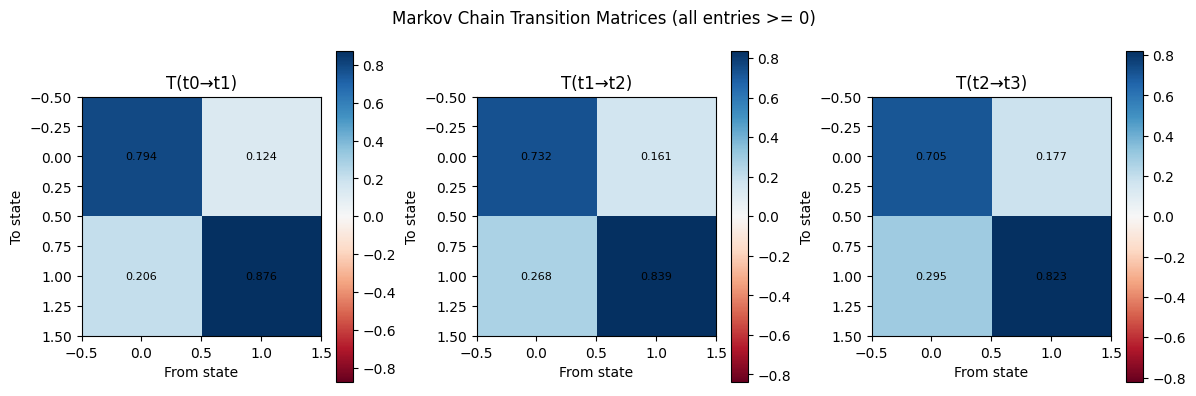

In [7]:
# Visualize the transition matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, ax in enumerate(axes):
    plot_transition_matrix(markov.transitions[i],
                           title=f"T(t{i}\u2192t{i+1})", ax=ax)
plt.suptitle("Markov Chain Transition Matrices (all entries >= 0)")
plt.tight_layout()
plt.show()

<!-- expansion:02:howto-plot -->
### 🧭 What to look at in the figure

Heatmaps of the first three steps of the Markov chain above ($e^{0.5L}$, $e^{0.7L}$, $e^{0.8L}$; the fourth is not plotted), each square annotated to three decimals.

- The horizontal axis is "From state", so each **column** is one starting state's outgoing distribution and should sum to 1.
- The colour map is red-white-blue, symmetric about zero; per the function's docstring, *"Negative entries appear in red — a visual signal of indivisibility."* Nothing here should be red.
- The first panel equals step 0 of the previous cell's process (same $L$, same 0.5), whose minimum printed as `+0.1236`.
- As the step grows, off-diagonals should grow and columns drift toward $\pi = (0.375, 0.625)$.

**Try this.** Plot `np.linalg.inv(markov.transitions[0])`. Predict red off-diagonal squares: the pseudo-stochastic inverse the test multiplies by but never accepts on its own.


<!-- expansion:02:deriv-preview -->
### 🧮 Worked derivation: watching divisibility fail in a two-state family

This uses Section 2's eigenvalue idea on the family Barandes uses as his first example (2302.10778v3, eq. 7), which is also the form of notebook 03's qubit.

**Setup.** With "stay" probability $f$ and $\lambda = 2f - 1$,

$$M(\lambda) = \frac12\begin{pmatrix}1 + \lambda & 1 - \lambda\\ 1 - \lambda & 1 + \lambda\end{pmatrix},$$

stochastic exactly when $|\lambda| \le 1$, with eigenvectors $(1,1)^{\mathsf T}$ (eigenvalue 1) and $(1,-1)^{\mathsf T}$ (eigenvalue $\lambda$).

**Step 1.** Shared eigenvectors give $M(\lambda)M(\mu) = M(\lambda\mu)$ (check: $\tfrac14[(1+\lambda)(1+\mu) + (1-\lambda)(1-\mu)] = \tfrac12(1 + \lambda\mu)$), and $M(\lambda)^{-1} = M(1/\lambda)$ for $\lambda \ne 0$.

**Step 2.** If $\Gamma(t \leftarrow 0) = M(\lambda(t))$, the candidate bridge is $M(\lambda(t))\,M(\lambda(t'))^{-1} = M\big(\lambda(t)/\lambda(t')\big)$.

**Step 3.** That is stochastic exactly when $|\lambda(t)| \le |\lambda(t')|$. So, for this family,

$$\text{divisible at every time} \iff |2f(t) - 1| \text{ never increases}.$$

If it ever rises, take $t'$ before the rise and $t$ after: an entry goes negative (`negative_entries`). If $\lambda(t') = 0$, $M$ is Section 1's rank-1 matrix (`singular_matrix`).

**Applying it.**
- Symmetric Markov chain, flip rate $r$: $\lambda = e^{-2rt}$, decreasing. Divisible.
- Barandes' $f = e^{-t^2/\tau^2}$: $\lambda$ falls from 1 through 0 at $t = \tau\sqrt{\ln 2}$ toward $-1$, so $|\lambda|$ falls then rises. Indivisible, matching the paper's *"provably indivisible"*.
- Barandes' $f = \cos^2\omega t$ and notebook 03's $f = \cos^2(\omega t/2)$: $|\lambda|$ oscillates. Indivisible.

Every $\Gamma(t \leftarrow 0)$ here is valid at every $t$; only bridges fail. (For general matrices the test is the LP, not this rule.)


### 🔭 Looking ahead: P-divisibility, CP-divisibility, and where this condition sits

Anyone arriving from quantum information will recognize the word "divisibility" and should be warned that it names a *related but distinct* condition there. Keeping them apart avoids importing results that do not apply.

#### The open-systems hierarchy

Open quantum dynamics is written with **dynamical maps** acting on density matrices, $\rho(t) = \Lambda(t,t_0)\,\rho(t_0)$, and the same factorization question is asked of them:

$$\Lambda(t_2,t_0) \;=\; \Lambda(t_2,t_1)\,\Lambda(t_1,t_0)$$

The literature then grades the intermediate map:

| condition | requirement on $\Lambda(t_2,t_1)$ | usual name |
|---|---|---|
| P-divisible | positive and trace preserving | weaker |
| CP-divisible | **completely** positive and trace preserving | the standard definition of quantum Markovianity |

CP-divisibility is what the Rivas–Huelga–Plenio measure detects, and its violation is the usual working definition of non-Markovian open-system dynamics. `papers to study/Quantum Non-Markovianity Rivas.pdf` and `Dividing Quantum Channels.pdf` are the two references on the shelf for this.

#### Why it is a different object here

The divisibility tested in these notebooks is not applied to a dynamical map on density matrices. It is applied to the **stochastic matrix on configurations**,

$$\Gamma(t_j,t_i)_{kl} \;=\; \big|U(t_j,t_i)_{kl}\big|^2$$

which is a real, non-negative, column-stochastic matrix — an object of classical probability. The unknown being solved for is a transition matrix, not a channel; the constraint is non-negativity of probabilities, not complete positivity of a superoperator.

| | this lab (Barandes) | open-systems literature |
|---|---|---|
| acts on | probability distributions over configurations | density matrices |
| the object | $\Gamma$, column-stochastic | $\Lambda$, a CPTP map |
| what may fail | entries of the intermediate go negative | intermediate map is not CP (or not P) |
| system in this notebook | closed and unitary (ISPs in general need not be) | open, coupled to an environment |

That last row is the one that most often trips people. In the open-systems framing, non-Markovianity arises because information leaks into an environment and returns. Here **the system is closed and the evolution is exactly unitary** — there is no environment at all — and indivisibility appears anyway. It is a property of how a unitary's Born-rule probabilities compose, not a symptom of a bath. The point is Barandes's (Paper 3, §1, p. 3), and he credits Glick and Adami (2020, arXiv:1701.05636) with showing that a form of non-Markovianity is intrinsic to closed quantum systems.

> ⚠️ **The two conditions are independent.** A closed qubit is CP-divisible (its $U(t \leftarrow t')$ is unitary, Paper 1, eq. 40), yet $\Gamma = |U|^2$ is indivisible (notebook 03), and notebook 08 shows all four combinations under dephasing. Comparisons of the classical and quantum notions are in the literature (Vacchini et al. 2011). Do not carry results from one hierarchy to the other on the strength of the shared word.

<!-- expansion:02:papers-wolf-cirac -->
### 📚 From the papers: the two channel references above

- **Wolf and Cirac, *Dividing Quantum Channels* (arXiv:math-ph/0611057v3), §IV, Definition 8.** A channel is *indivisible* if *"every decomposition of the form $T = T_1T_2$ ... is such that one of the $T_i$ has to be a unitary conjugation."* That is a property of **one** map, not of a time-indexed family at a chosen intermediate time. Barandes borrows the word from this paper, not the definition.
- **Rivas, Huelga and Plenio, §3.2.** Because *"the classical definition of Markovianity reduces to the concept of divisibility"* for one-time probabilities, they grade the intermediate map: positive gives a *P-divisible* process (Definition 3.1), completely positive gives their definition of a *Markovian* quantum process (Definition 3.2).

Neither source supplies a theorem linking the two, consistent with the warning above: they are independent conditions, as notebook 08 shows.


<!-- expansion:02:recap-2 -->
### 📝 Recap: Section 2

- $e^{L(t_3 - t_1)} = e^{L(t_3 - t_2)}e^{L(t_2 - t_1)}$ because the exponents commute, and $e^{Lt}$ is stochastic exactly for valid generators (Norris, Thms 2.1.1 and 2.1.2).
- Any process assembled from valid stochastic steps passes, including time-inhomogeneous ones.
- Divisible is strictly larger than Markov, but indistinguishable from it using one-time distributions (Rivas et al., Cor. 2.2). Ordinary memory does not cause indivisibility.
- Long time steps can make the inverse test report `singular_matrix` on a divisible chain.
- For symmetric two-state matrices, divisibility means "$|2f - 1|$ never increases"; notebook 03's qubit breaks it.

### 🔭 Looking ahead: why this matters for search

In `notes/grover-as-isp-spike-2026-10-23.md` (feeding notebook 09), the Grover oracle has $\Gamma(O) = |O|^2 = I$ because it only flips a sign, and the spike records *"$\Gamma(D)\Gamma(O) = \Gamma(D)$ for every marked item. The divisible (Markov) composition has lost the oracle entirely."* The marked item reaches the probabilities only through indivisibility across queries. That is an exploratory spike result, not something this notebook shows.


## Summary

- Divisibility means the process can always be factored through any intermediate time
- The intermediate matrix must be non-negative with columns summing to 1
- Markov chains are always divisible — $T(t) = e^{Lt}$ guarantees it

**Next:** Notebook 03 constructs a process that *fails* this test —
and sees what quantum mechanics looks like from the stochastic side.

<!-- expansion:02:final-recap -->
### 📝 Notebook recap and where to go next

**You should now be able to:**
- state divisibility as Barandes' eq. 6, with a *genuinely stochastic* bridge;
- explain why the inverse-based candidate always has unit column sums and only non-negativity can fail;
- read `check_divisibility()` correctly: `negative_entries` is a verdict, `singular_matrix` is "inconclusive", `normalization_violated` is round-off;
- explain why every Markov chain is divisible, and why divisible does not mean Markov;
- predict when a symmetric two-state process becomes indivisible.

**Left open here:** singular times need the LP (`check_divisibility_lp`); environments creating division events is stated, not shown (notebook 06); no link to CP-divisibility is established.

**Next:** open `03_indivisibility_annotated.ipynb`. It takes the qubit process $\Gamma_{ij}(t \leftarrow 0) = |U_{ij}(t)|^2$, with stay probability $\cos^2(\omega t/2)$, runs the same `check_divisibility()`, and finds the `negative_entries` failure the two-state derivation predicts. To revisit the basics, see `01_stochastic_processes_annotated.ipynb`.
